# Customer Churn Prediction

## 1. Data Loading and Understanding

In [ ]:
import warnings
warnings.filterwarnings('ignore')

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

In [36]:
import os

DATA_URL = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
BASE_NAME = "WA_Fn-UseC_-Telco-Customer-Churn"

data_path = None
for name in (BASE_NAME + ".csv", BASE_NAME + ".xlsx", "Telco-Customer-Churn.csv"):
    if os.path.exists(name):
        data_path = name
        break

if data_path is None:
    try:
        pd.read_csv(DATA_URL).to_csv("Telco-Customer-Churn.csv", index=False)
        data_path = "Telco-Customer-Churn.csv"
        print("Dataset downloaded automatically.")
    except Exception as e:
        print("Auto-download failed:", e)
        from google.colab import files
        print("Please upload the Telco Churn .csv or .xlsx file")
        uploaded = files.upload()
        data_path = list(uploaded.keys())[0]

if data_path.lower().endswith(".csv"):
    df = pd.read_csv(data_path)
else:
    df = pd.read_excel(data_path)

df.columns = df.columns.str.strip()

# Sanity check: make sure this is the right dataset
required = ['customerID', 'tenure', 'MonthlyCharges', 'TotalCharges', 'Contract', 'Churn']
missing = [c for c in required if c not in df.columns]
if missing:
    raise ValueError(
        "Wrong dataset loaded (file: " + data_path + "). Missing columns: " + str(missing) +
        "\nColumns found: " + str(df.columns.tolist()) +
        "\nDelete that file from the Colab Files panel and re-run this cell."
    )
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [ ]:
print(df.shape)

(7043, 21)


In [ ]:
print(df.columns.tolist())

['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


In [ ]:
df.dtypes

,0
customerID,object
gender,object
SeniorCitizen,int64
Partner,object
Dependents,object
tenure,int64
PhoneService,object
MultipleLines,object
InternetService,object
OnlineSecurity,object


In [ ]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [ ]:
df['Churn'].value_counts()

,count
Churn,
No,5174
Yes,1869


## 2. Data Preprocessing

In [ ]:
df.isnull().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
df['TotalCharges'].isnull().sum()

np.int64(11)

In [ ]:
df = df.dropna()
df.shape

(7032, 21)

In [ ]:
df = df.drop('customerID', axis=1)
df.dtypes

,0
gender,object
SeniorCitizen,int64
Partner,object
Dependents,object
tenure,int64
PhoneService,object
MultipleLines,object
InternetService,object
OnlineSecurity,object
OnlineBackup,object


## 3. Exploratory Data Analysis

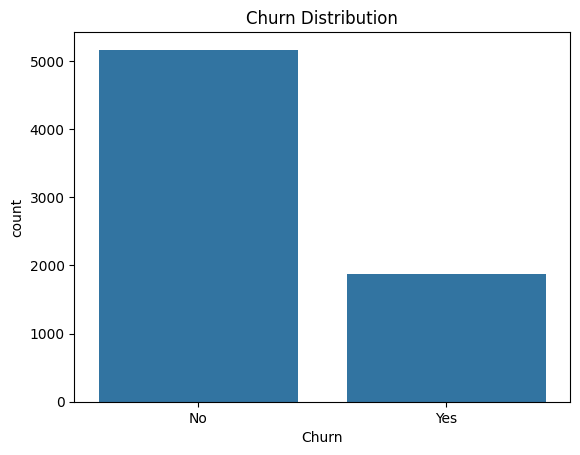

In [ ]:
sns.countplot(x='Churn', data=df)
plt.title('Churn Distribution')
plt.show()

In [ ]:
df['Churn'].value_counts(normalize=True) * 100

,proportion
Churn,
No,73.421502
Yes,26.578498


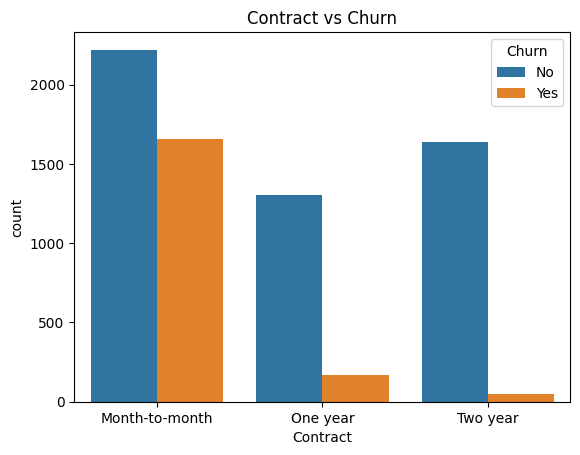

In [ ]:
sns.countplot(x='Contract', hue='Churn', data=df)
plt.title('Contract vs Churn')
plt.show()

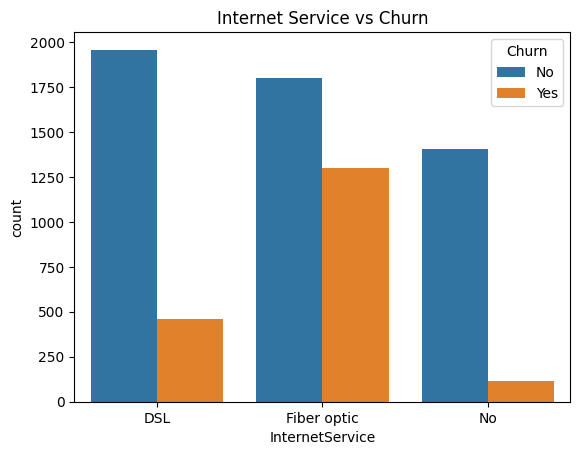

In [ ]:
sns.countplot(x='InternetService', hue='Churn', data=df)
plt.title('Internet Service vs Churn')
plt.show()

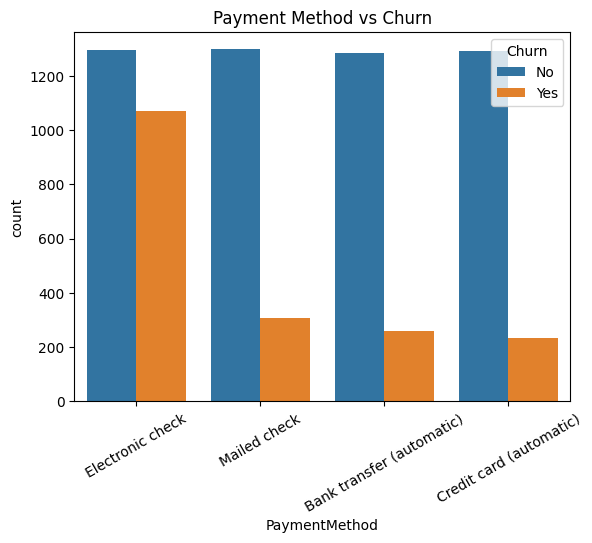

In [ ]:
sns.countplot(x='PaymentMethod', hue='Churn', data=df)
plt.xticks(rotation=30)
plt.title('Payment Method vs Churn')
plt.show()

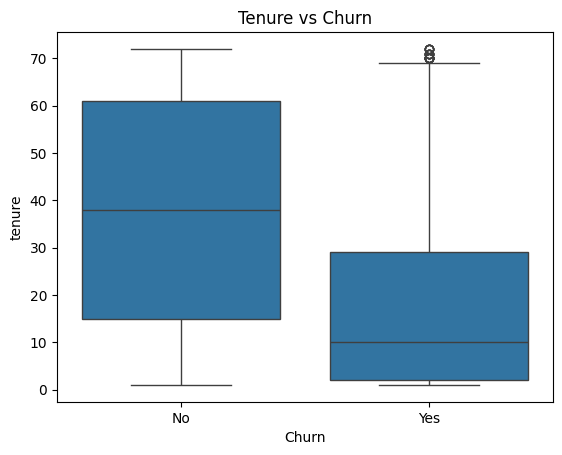

In [ ]:
sns.boxplot(x='Churn', y='tenure', data=df)
plt.title('Tenure vs Churn')
plt.show()

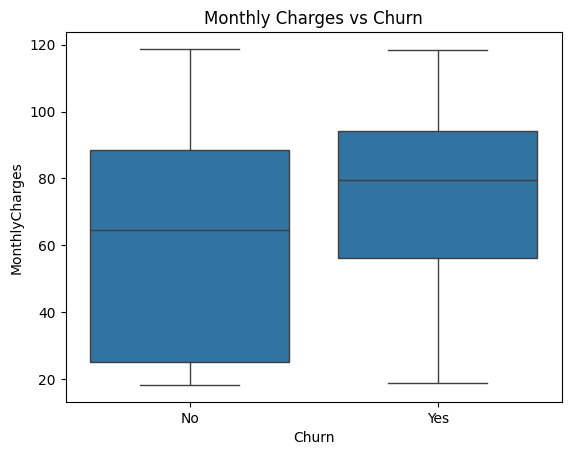

In [ ]:
sns.boxplot(x='Churn', y='MonthlyCharges', data=df)
plt.title('Monthly Charges vs Churn')
plt.show()

In [ ]:
df.groupby('Churn')[['tenure', 'MonthlyCharges', 'TotalCharges']].mean()

,tenure,MonthlyCharges,TotalCharges
Churn,,,
No,37.650010,61.307408,2555.344141
Yes,17.979133,74.441332,1531.796094


## 4. Feature Engineering and Encoding

In [ ]:
df['Churn'] = df['Churn'].astype(str).str.strip().map({'Yes': 1, 'No': 0})
df['Churn'].value_counts()

,count
Churn,
0,5163
1,1869


In [ ]:
df_encoded = pd.get_dummies(df, drop_first=True, dtype=int)
df_encoded.head()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,Churn,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,...,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,29.85,29.85,0,0,1,0,0,1,...,0,0,0,0,0,0,1,0,1,0
1,0,34,56.95,1889.50,0,1,0,0,1,0,...,0,0,0,0,1,0,0,0,0,1
2,0,2,53.85,108.15,1,1,0,0,1,0,...,0,0,0,0,0,0,1,0,0,1
3,0,45,42.30,1840.75,0,1,0,0,0,1,...,0,0,0,0,1,0,0,0,0,0
4,0,2,70.70,151.65,1,0,0,0,1,0,...,0,0,0,0,0,0,1,0,1,0


In [ ]:
X = df_encoded.drop('Churn', axis=1)
y = df_encoded['Churn']
print(X.shape)
print(y.shape)

(7032, 30)
(7032,)


## 5. Training and Testing

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print(X_train.shape, X_test.shape)

(5625, 30) (1407, 30)


In [ ]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [ ]:
lr = LogisticRegression(max_iter=1000)
lr.fit(X_train_scaled, y_train)

LogisticRegression(max_iter=1000)

In [ ]:
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train_scaled, y_train)

RandomForestClassifier(random_state=42)

## 6. Model Evaluation

In [ ]:
lr_pred = lr.predict(X_test_scaled)
rf_pred = rf.predict(X_test_scaled)

results = pd.DataFrame({
    'Model': ['Logistic Regression', 'Random Forest'],
    'Accuracy': [accuracy_score(y_test, lr_pred), accuracy_score(y_test, rf_pred)],
    'Precision': [precision_score(y_test, lr_pred), precision_score(y_test, rf_pred)],
    'Recall': [recall_score(y_test, lr_pred), recall_score(y_test, rf_pred)],
    'F1-Score': [f1_score(y_test, lr_pred), f1_score(y_test, rf_pred)]
})
results

,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.803838,0.647590,0.574866,0.609065
1,Random Forest,0.788202,0.623377,0.513369,0.563050


In [ ]:
print(classification_report(y_test, lr_pred))

              precision    recall  f1-score   support

           0       0.85      0.89      0.87      1033
           1       0.65      0.57      0.61       374

    accuracy                           0.80      1407
   macro avg       0.75      0.73      0.74      1407
weighted avg       0.80      0.80      0.80      1407



In [ ]:
print(classification_report(y_test, rf_pred))

              precision    recall  f1-score   support

           0       0.83      0.89      0.86      1033
           1       0.62      0.51      0.56       374

    accuracy                           0.79      1407
   macro avg       0.73      0.70      0.71      1407
weighted avg       0.78      0.79      0.78      1407



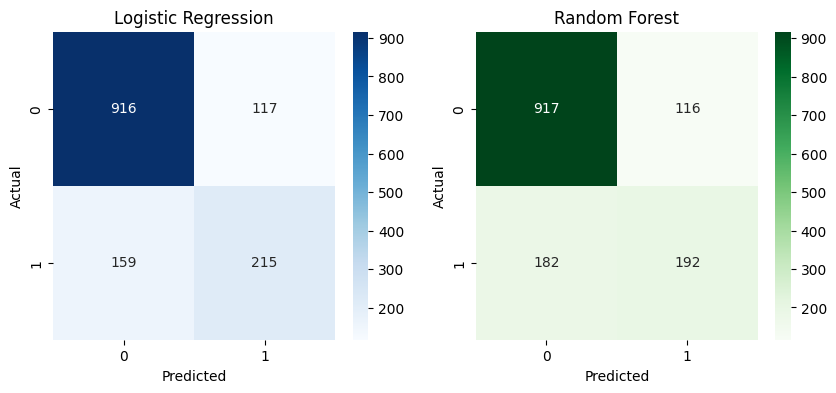

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
sns.heatmap(confusion_matrix(y_test, lr_pred), annot=True, fmt='d', cmap='Blues', ax=ax[0])
ax[0].set_title('Logistic Regression')
ax[0].set_xlabel('Predicted')
ax[0].set_ylabel('Actual')
sns.heatmap(confusion_matrix(y_test, rf_pred), annot=True, fmt='d', cmap='Greens', ax=ax[1])
ax[1].set_title('Random Forest')
ax[1].set_xlabel('Predicted')
ax[1].set_ylabel('Actual')
plt.show()

In [ ]:
if f1_score(y_test, lr_pred) >= f1_score(y_test, rf_pred):
    final_model = lr
    print('Final model: Logistic Regression')
else:
    final_model = rf
    print('Final model: Random Forest')

Final model: Logistic Regression


## 7. Application / Prediction






In [ ]:
new_customers = pd.DataFrame([
    {'gender': 'Female', 'SeniorCitizen': 0, 'Partner': 'No', 'Dependents': 'No', 'tenure': 2,
     'PhoneService': 'Yes', 'MultipleLines': 'No', 'InternetService': 'Fiber optic',
     'OnlineSecurity': 'No', 'OnlineBackup': 'No', 'DeviceProtection': 'No', 'TechSupport': 'No',
     'StreamingTV': 'No', 'StreamingMovies': 'No', 'Contract': 'Month-to-month',
     'PaperlessBilling': 'Yes', 'PaymentMethod': 'Electronic check',
     'MonthlyCharges': 85.5, 'TotalCharges': 171.0},
    {'gender': 'Male', 'SeniorCitizen': 0, 'Partner': 'Yes', 'Dependents': 'Yes', 'tenure': 60,
     'PhoneService': 'Yes', 'MultipleLines': 'Yes', 'InternetService': 'DSL',
     'OnlineSecurity': 'Yes', 'OnlineBackup': 'Yes', 'DeviceProtection': 'Yes', 'TechSupport': 'Yes',
     'StreamingTV': 'No', 'StreamingMovies': 'No', 'Contract': 'Two year',
     'PaperlessBilling': 'No', 'PaymentMethod': 'Bank transfer (automatic)',
     'MonthlyCharges': 65.0, 'TotalCharges': 3900.0}
])
new_customers

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
0,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,85.5,171.0
1,Male,0,Yes,Yes,60,Yes,Yes,DSL,Yes,Yes,Yes,Yes,No,No,Two year,No,Bank transfer (automatic),65.0,3900.0


In [ ]:
new_encoded = pd.get_dummies(new_customers, dtype=int)
new_encoded = new_encoded.reindex(columns=X.columns, fill_value=0)
new_scaled = scaler.transform(new_encoded)

In [ ]:
predictions = final_model.predict(new_scaled)
probabilities = final_model.predict_proba(new_scaled)[:, 1]

for i in range(len(predictions)):
    if predictions[i] == 1:
        result = 'Churn'
    else:
        result = 'No Churn'
    print('Customer', i + 1, '->', result, '(churn probability:', round(probabilities[i], 2), ')')

Customer 1 -> Churn (churn probability: 0.59 )
Customer 2 -> No Churn (churn probability: 0.01 )
